# OSM multi-hop spatial questions: can they be framed as KGQA?

**Data** (`data/osm/`, 5 tables): Paris points of interest (POIs) from OpenStreetMap, the streets and areas around
them, and 1.18M template-generated questions such as *"restaurant indian food at less than 1000 meters from
[cafe … near Le Florida and following Rue de Cléry]"*. Each question's answer is a **set of POI ids**.

**Question this notebook answers:** can the questions be cast as knowledge-graph question answering, with
graph = POIs + streets + areas linked by spatial relations, question = a path over that graph, and answer =
named POIs?

**How:** link every entity mentioned in the questions to the tables (§5), recover the meaning of each relation
from the gold answers' geometry (§6), materialise the graph (§7), then **re-answer the questions from the
graph alone** and compare with the gold sets (§8). §9 walks through one 3-hop question, and §10 proposes a
KGQA sample format.

Helpers (WKB decoding, question parser, relation rules, solver) are in [`scripts/osm/osm_kg.py`](../scripts/osm/osm_kg.py).

## 1. Setup

In [1]:
import sys, re, collections, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import networkx as nx

sys.path.insert(0, str(Path.cwd().parent / "scripts" / "osm"))  # osm_kg.py
import osm_kg as K

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Chart style: light surface, recessive axes, fixed categorical order (blue, orange, aqua), gray = "other".
C = dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781", grid="#e1e0d9", axis="#c3c2b7",
         blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", red="#e34948", other="#b4b2a9")
SEQ = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]  # ordinal blue ramp (depth 1..4 / hop 1..4)
mpl.rcParams.update({
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 9,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
    "font.family": "sans-serif", "figure.dpi": 110,
})

## 2. The five tables

`df_osm.poi_id` is the id space of `df_multihop.answers`. Streets and areas have no id in the questions: they
are referred to **by name** in the question text. Geometries are WKB in Lambert-93 (EPSG:2154, metres).

In [2]:
kg = K.load()                       # all five tables + decoded geometries + KD-tree (~5 s)
mh = kg.multihop

overview = pd.DataFrame([
    ("df_osm", len(kg.poi), "POI: poi_id, name, category, cuisine, seating, x/y", "answers, POI anchors"),
    ("df_street", len(kg.street), "street polyline + name", "anchors of `following`, `intersection`"),
    ("df_area", len(kg.area), "polygon + name + category", "anchors of `inside`, `border`, `at the N/S/E/W of`"),
    ("df_multihop", len(mh), "nested question text, answer poi_ids, clauses per level", "questions"),
    ("df_dump_question", len(kg.dump), "flat question text, answers, depth (200 per depth)", "eval subset"),
], columns=["table", "rows", "content", "role"])
overview

,table,rows,content,role
0,df_osm,17457,"POI: poi_id, name, category, cuisine, seating, x/y","answers, POI anchors"
1,df_street,7193,street polyline + name,"anchors of `following`, `intersection`"
2,df_area,1046,polygon + name + category,"anchors of `inside`, `border`, `at the N/S/E/W of`"
3,df_multihop,1177868,"nested question text, answer poi_ids, clauses per level",questions
4,df_dump_question,800,"flat question text, answers, depth (200 per depth)",eval subset


In [3]:
mh.head(3)

,index,index_origin,index_lateral,query_texte,features,values,answers,template,dic_query,description_textuelle
0,44335,10575,"[44309, 44323]",[restaurant israeli food without outdoor seating between Les Boulevards and James Hetfeeld’s and at the intersection...,"[category, cooking_type, outdoor_seating]","[restaurant, israeli, no]",[9818],"[3, 0]","[[10575, 44309, 44323], []]",Restaurant israeli food without outdoor seating between Les Boulevards and James Hetfeeld’s and at the intersection ...
1,44336,10575,"[44284, 44287]",[restaurant israeli food without outdoor seating between Les Boulevards and James Hetfeeld’s and between Sentier and...,"[category, cooking_type, outdoor_seating]","[restaurant, israeli, no]",[9818],"[3, 0]","[[10575, 44284, 44287], []]",Restaurant israeli food without outdoor seating between Les Boulevards and James Hetfeeld’s and between Sentier and ...
2,44337,10575,"[44267, 44271]",[restaurant israeli food without outdoor seating between Les Boulevards and James Hetfeeld’s and inside Paris 2e Arr...,"[category, cooking_type, outdoor_seating]","[restaurant, israeli, no]",[9818],"[3, 0]","[[10575, 44267, 44271], []]",Restaurant israeli food without outdoor seating between Les Boulevards and James Hetfeeld’s and inside Paris 2e Arro...


**`df_multihop` columns.**
- `query_texte`: the question with sub-questions nested in `[...]`.
- `description_textuelle`: the same question flattened into one sentence per hop, with nested sub-questions
  replaced by their category word.
- `answers`: `poi_id`s.
- `features` / `values`: the attribute filter of the outermost level.
- `template[i]`: the number of clauses at level *i*, outermost first; 0 terminates the list. Depth = `len(template) - 1`.
- `index_*`, `dic_query`: ids of the generator's constraint objects. They point to no table here and are not
  needed.

**Duplicates.** A plain `drop_duplicates()` fails here: the array columns are unhashable, and `index` is
unique anyway. Deduplicate on the question text instead:

In [4]:
dup = mh.duplicated("query_texte")
print(f"{dup.sum():,} rows repeat a question text ({dup.mean():.2%}); "
      f"{mh[dup].answers.map(len).sum():,} answer ids in them")
mh = mh[~dup].copy()                 # the row labels stay the original positions (df_dump_question uses them)
mh["depth"] = mh.template.map(len) - 1
mh["n_answers"] = mh.answers.map(len)

1,603 rows repeat a question text (0.14%); 1,798 answer ids in them


## 3. Entities: POIs, streets and areas

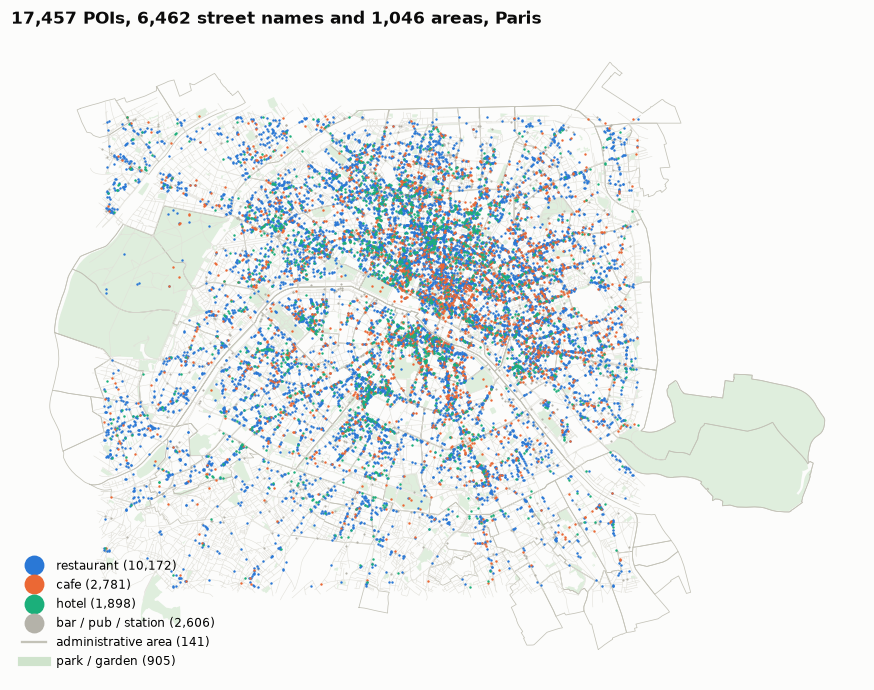

In [5]:
poi = kg.poi
main = ["restaurant", "cafe", "hotel"]                      # three categorical slots; the rest folds into gray
colors = {"restaurant": C["blue"], "cafe": C["orange"], "hotel": C["aqua"]}

fig, ax = plt.subplots(figsize=(10, 8.2))
for name, g in kg.area_geom.items():                        # administrative areas as outlines, parks filled
    cat = kg.area.category[kg.area.area_name == name].iloc[0]
    for rings in K.polygons(g):
        if cat == "administrative":
            ax.plot(*rings[0].T, color=C["axis"], lw=0.5, zorder=1)
        else:
            ax.fill(*rings[0].T, color="#dfeedd", lw=0, zorder=0)
for lines in kg.street_lines.values():
    for line in lines:
        ax.plot(*line.T, color=C["grid"], lw=0.35, zorder=1)
other = ~poi.category.isin(main)
ax.scatter(poi.x[other], poi.y[other], s=2, color=C["other"], lw=0, zorder=2)
for cat in main:
    m = poi.category == cat
    ax.scatter(poi.x[m], poi.y[m], s=2.5, color=colors[cat], lw=0, zorder=3)
handles = [Line2D([], [], marker="o", ls="", color=colors[c], label=f"{c} ({(poi.category == c).sum():,})") for c in main]
handles += [Line2D([], [], marker="o", ls="", color=C["other"], label=f"bar / pub / station ({other.sum():,})"),
            Line2D([], [], color=C["axis"], label=f"administrative area ({(kg.area.category == 'administrative').sum()})"),
            Line2D([], [], color="#cfe3cc", lw=6, label=f"park / garden ({(kg.area.category != 'administrative').sum()})")]
ax.legend(handles=handles, loc="lower left", markerscale=2)
ax.set_aspect("equal"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
ax.set_title(f"{len(poi):,} POIs, {len(kg.street_lines):,} street names and {len(kg.area):,} areas, Paris")
plt.show()

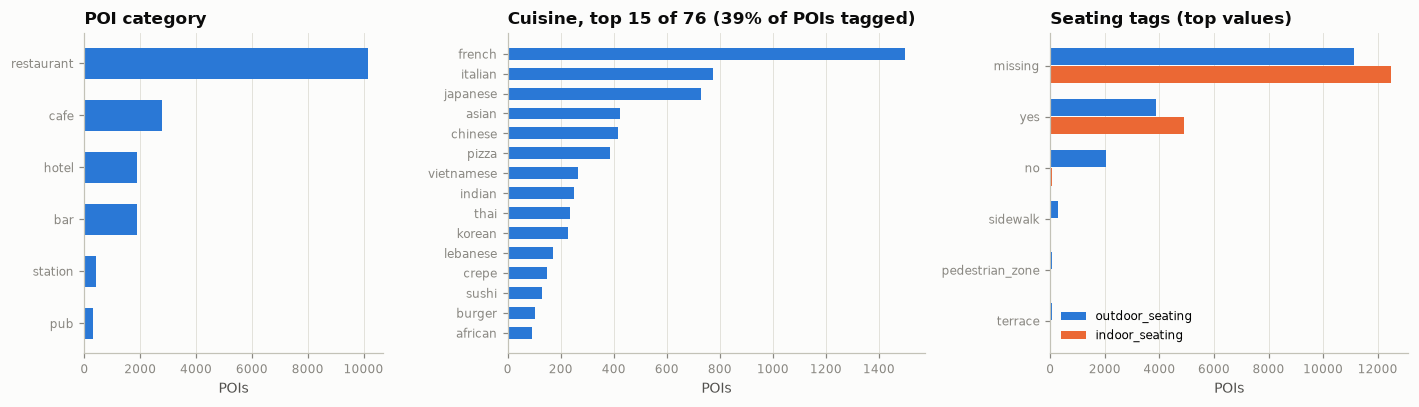

POI names: 15,657 distinct for 17,457 POIs; 1,092 names are shared by several POIs (e.g. Starbucks, Pizza Hut, Ibis, Le Rallye).


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1, 1.4, 1.2]))
vc = poi.category.value_counts()
axes[0].barh(vc.index[::-1], vc.values[::-1], color=C["blue"], height=0.6)
axes[0].set_title("POI category")
ct = poi.cooking_type.value_counts().head(15)
axes[1].barh(ct.index[::-1], ct.values[::-1], color=C["blue"], height=0.6)
axes[1].set_title(f"Cuisine, top 15 of {poi.cooking_type.nunique()} ({poi.cooking_type.notna().mean():.0%} of POIs tagged)")
seat = pd.DataFrame({k: poi[c].fillna("missing").value_counts() for k, c in
                     [("outdoor", "outdoor_seating"), ("indoor", "indoor_seating")]}).fillna(0)
seat = seat.loc[seat.sum(axis=1).sort_values().index[-6:]]
y = np.arange(len(seat))
axes[2].barh(y + 0.18, seat["outdoor"], height=0.34, color=C["blue"], label="outdoor_seating")
axes[2].barh(y - 0.18, seat["indoor"], height=0.34, color=C["orange"], label="indoor_seating")
axes[2].set_yticks(y, seat.index); axes[2].legend(); axes[2].set_title("Seating tags (top values)")
for a in axes: a.grid(axis="y", visible=False); a.set_xlabel("POIs")
plt.tight_layout(); plt.show()

amb = poi.poi_name.value_counts()
print(f"POI names: {poi.poi_name.nunique():,} distinct for {len(poi):,} POIs; "
      f"{(amb > 1).sum():,} names are shared by several POIs (e.g. {', '.join(amb.index[:4])}).")

## 4. Questions

Each question is a chain of 1–4 levels. The innermost level filters POIs by attributes and named anchors.
Every outer level filters POIs by attributes, by **one spatial relation to the previous level's answer set**,
and optionally by more named anchors.

In [7]:
ex = kg.dump.groupby("depth").head(1).sort_values("depth")
for d, q in zip(ex.depth, ex["query"]):
    print(f"depth {d}:", textwrap.fill(q, 150, subsequent_indent="         "), "\n")

depth 1: Restaurant noodle food to the west of Hôtel Canal Saint-Martin and at less than 500 meters from Cristal Bar and near Peak. 

depth 2: Pub to the south of cafe. Cafe with indoor seating near Le 15ème Boulevard towards Arthur et Juliette and at the intersection of Rue d'Alleray and
         Villa Hersent and to the west of Le Marché. 

depth 3: Restaurant pizza food on sidewalk at less than 500 meters from restaurant. Restaurant at less than 100 meters from restaurant and at the intersection
         of Rue Larochelle and Rue de la Gaîté and inside Paris 14e Arrondissement. Restaurant lebanese food with indoor seating between Pub Gaité and
         Paris Montparnasse 3 - Vaugirard and at the intersection of Rue Larochelle and Rue de la Gaîté and to the north of Pullman Paris
         Montparnasse. 

depth 4: Restaurant at less than 100 meters from restaurant. Restaurant vietnamese food with indoor seating to the south of cafe and at the intersection of Rue
         Léon-Maurice 

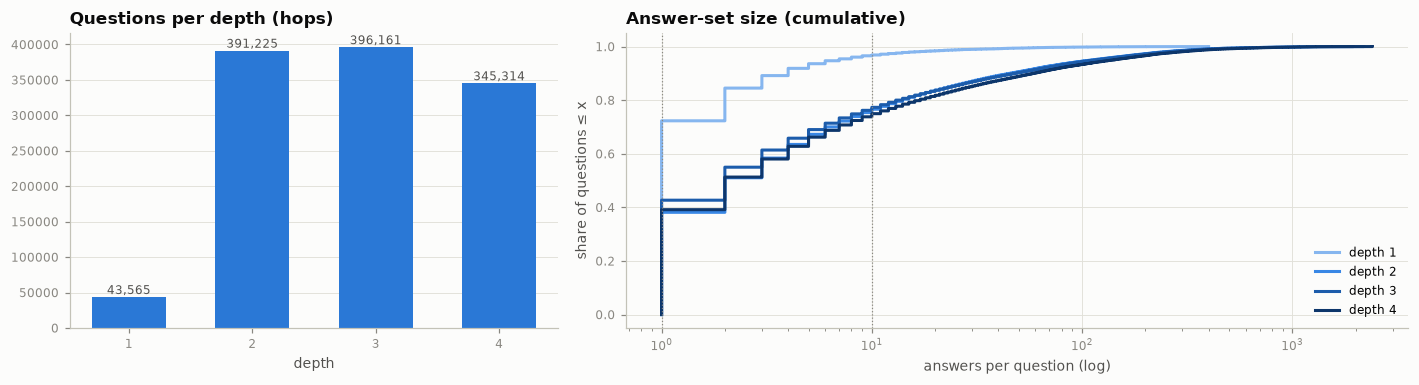

,mean,50%,90%,max,share =1,share ≤10
depth,,,,,,
1,2.65,1.0,4.0,400.0,0.72,0.97
2,23.08,2.0,45.0,2192.0,0.38,0.77
3,23.56,2.0,48.0,1954.0,0.43,0.77
4,27.54,2.0,59.0,2406.0,0.39,0.75


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1, 1.6]))
dc = mh.depth.value_counts().sort_index()
axes[0].bar(dc.index.astype(str), dc.values, color=C["blue"], width=0.6)
for x, v in zip(range(len(dc)), dc.values):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=C["ink2"])
axes[0].set_title("Questions per depth (hops)"); axes[0].set_xlabel("depth"); axes[0].grid(axis="x", visible=False)

for d, col in zip(range(1, 5), SEQ):
    s = np.sort(mh.n_answers[mh.depth == d].to_numpy())
    axes[1].step(s, np.arange(1, len(s) + 1) / len(s), where="post", color=col, lw=2, label=f"depth {d}")
axes[1].set_xscale("log"); axes[1].set_xlabel("answers per question (log)"); axes[1].set_ylabel("share of questions ≤ x")
axes[1].set_title("Answer-set size (cumulative)"); axes[1].legend(loc="lower right")
for x in (1, 10):
    axes[1].axvline(x, color=C["muted"], lw=0.8, ls=":")
plt.tight_layout(); plt.show()

sizes = mh.groupby("depth").n_answers.describe(percentiles=[.5, .9])[["mean", "50%", "90%", "max"]]
sizes["share =1"] = mh.groupby("depth").n_answers.apply(lambda s: (s == 1).mean())
sizes["share ≤10"] = mh.groupby("depth").n_answers.apply(lambda s: (s <= 10).mean())
sizes.round(2)

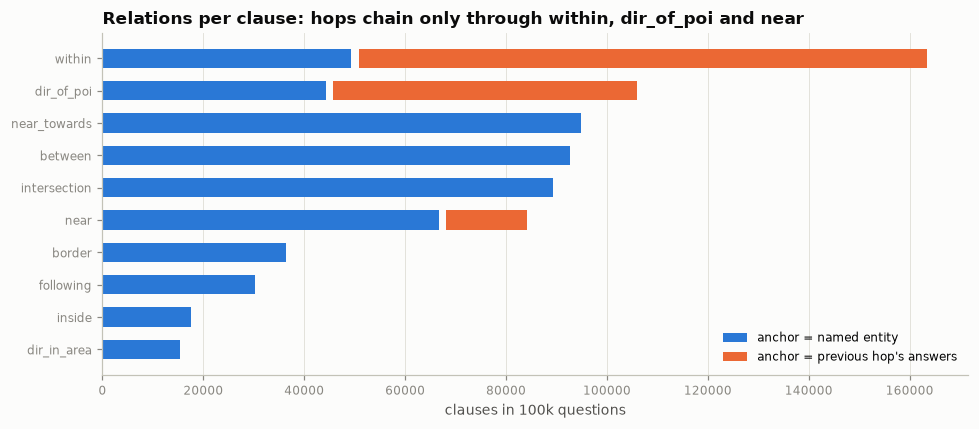

,phrase,anchor,rule (fitted in §6)
within,at less than N meters from X,POI / sub-question,"d(p, X) < N (N = 100, 300, 500, 1000)"
near,near X,POI / sub-question,"d(p, X) < 1000 m"
near_towards,near X towards Y,"POI, POI","d(p, X) < 1000 m and angle(X->p, X->Y) <= 90 deg"
dir_of_poi,"to the {N,S,E,W} of X",POI / sub-question,"d(p, X) < 1000 m and bearing X->p within 45 deg of the direction"
between,between X and Y,"POI, POI","d(p, segment XY) < 200 m"
intersection,at the intersection of S1 and S2,"street, street","d(p, crossing point of S1 and S2) < 1000 m"
following,following S,street,"d(p, S) < 50 m"
inside,inside A,area,p in polygon A
border,at the border of A,area,"d(p, boundary of A) < 200 m"
dir_in_area,"at the {N,S,E,W} of A",area,p in A and p on that side of the bbox centre of A


In [9]:
# Parse a sample of questions into levels and clauses (osm_kg.parse_question)
sample = mh.sample(100_000, random_state=0)
parsed = [K.parse_question(q) for q in sample.query_texte]
assert all(p.depth == d for p, d in zip(parsed, sample.depth))
counts = collections.Counter()
for p in parsed:
    for lvl in p.chain():
        for c in lvl.clauses:
            counts[(c.kind, "sub-question" if K.SUB in c.anchors else "named entity")] += 1
rel = (pd.Series(counts).unstack(fill_value=0).reindex(columns=["named entity", "sub-question"], fill_value=0))
rel = rel.loc[rel.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(rel.index, rel["named entity"], color=C["blue"], height=0.6, label="anchor = named entity")
ax.barh(rel.index, rel["sub-question"], left=rel["named entity"] + rel.values.sum() * 0.002, color=C["orange"],
        height=0.6, label="anchor = previous hop's answers")
ax.set_xlabel("clauses in 100k questions"); ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.set_title("Relations per clause: hops chain only through within, dir_of_poi and near")
plt.tight_layout(); plt.show()
pd.DataFrame(K.RELATIONS, index=["phrase", "anchor", "rule (fitted in §6)"]).T

## 5. Entity linking: do the questions refer to rows of the tables?

- **Answers:** every `poi_id` in `answers` exists in `df_osm`.
- **Named anchors:** each anchor is looked up by exact name in the table its relation expects.
  - "ambiguous" means the name belongs to several POIs.
  - Street names are never ambiguous: all segments with the same name form one street.

answer ids: 17,443 distinct, 17,443 found in df_osm (14 POIs are never an answer)


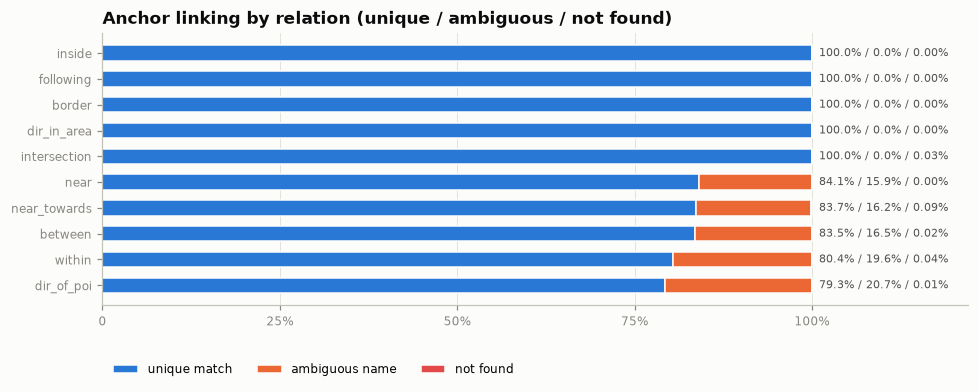

all anchors: 88.80% unique, 11.16% ambiguous, 0.036% not found


In [10]:
ans_ids = set(np.concatenate(mh.answers.to_numpy()).tolist())
print(f"answer ids: {len(ans_ids):,} distinct, {len(ans_ids & set(poi.poi_id)):,} found in df_osm "
      f"({len(set(poi.poi_id) - ans_ids):,} POIs are never an answer)")

table_names = {"poi": kg.by_name, "street": kg.street_lines, "area": kg.area_geom}
link = collections.Counter()
for p in parsed[:30_000]:
    for lvl in p.chain():
        for c in lvl.clauses:
            for a in c.anchors:
                if a == K.SUB:
                    continue
                tab = K.RELATION_ANCHOR[c.kind]
                if a not in table_names[tab]:
                    status = "not found"
                elif tab == "poi" and len(kg.by_name[a]) > 1:
                    status = "ambiguous name"
                else:
                    status = "unique match"
                link[(c.kind, status)] += 1
L = pd.Series(link).unstack(fill_value=0).reindex(columns=["unique match", "ambiguous name", "not found"], fill_value=0)
Lp = L.div(L.sum(axis=1), axis=0).sort_values("unique match")

fig, ax = plt.subplots(figsize=(9, 3.8))
left = np.zeros(len(Lp))
for col, colr in zip(Lp.columns, [C["blue"], C["orange"], C["red"]]):
    ax.barh(Lp.index, Lp[col], left=left, color=colr, height=0.6, label=col, edgecolor=C["surface"], lw=1)
    left += Lp[col].to_numpy()
for y, (u, a, n) in enumerate(Lp.to_numpy()):
    ax.text(1.01, y, f"{u:.1%} / {a:.1%} / {n:.2%}", va="center", fontsize=7.5, color=C["ink2"])
ax.set_xlim(0, 1.22); ax.set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, -0.3)); ax.grid(axis="y", visible=False)
ax.set_title("Anchor linking by relation (unique / ambiguous / not found)")
plt.tight_layout(); plt.show()
tot = L.sum()
print(f"all anchors: {tot['unique match'] / tot.sum():.2%} unique, {tot['ambiguous name'] / tot.sum():.2%} ambiguous, "
      f"{tot['not found'] / tot.sum():.3%} not found")

## 6. What each relation means geometrically

For 1-hop questions, every gold answer satisfies every clause. Measuring the gold answers against their
anchors therefore reveals each rule. The histograms below show the gold answers. A hard cut-off (dashed line)
with nothing beyond it means the relation is a deterministic, computable edge. Rare points beyond the line
come from ambiguous anchor names.

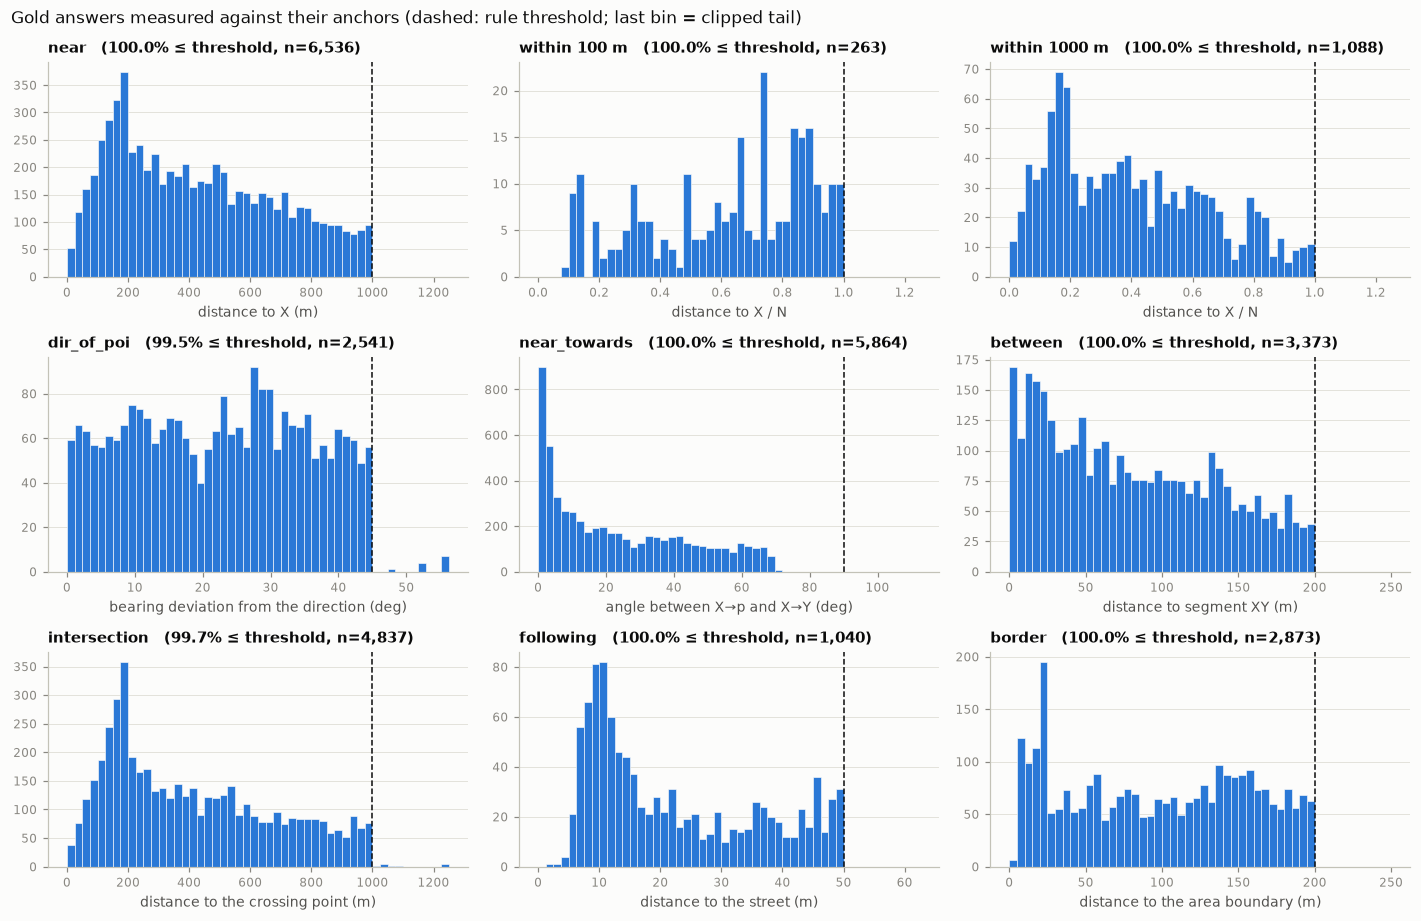

inside      : 100.0% of gold answers satisfy the polygon rule (n=680)
dir_in_area : 99.5% of gold answers satisfy the polygon rule (n=643)


In [11]:
one = mh[mh.depth == 1].sample(4000, random_state=1)
metrics = collections.defaultdict(list)
for q, ans in zip(one.query_texte, one.answers):
    lvl = K.parse_question(q)
    rows = kg.rows(ans)
    for c in lvl.clauses:
        try:
            v = K.clause_metric(kg, c, rows)
        except KeyError:
            continue
        key = f"within {c.param} m" if c.kind == "within" else c.kind
        metrics[key].extend(v / c.param if c.kind == "within" else v)

panels = [  # key, x label, threshold
    ("near", "distance to X (m)", K.NEAR_M),
    ("within 100 m", "distance to X / N", 1), ("within 1000 m", "distance to X / N", 1),
    ("dir_of_poi", "bearing deviation from the direction (deg)", 45),
    ("near_towards", "angle between X→p and X→Y (deg)", K.TOWARDS_DEG),
    ("between", "distance to segment XY (m)", K.BETWEEN_M),
    ("intersection", "distance to the crossing point (m)", K.INTER_M),
    ("following", "distance to the street (m)", K.FOLLOW_M),
    ("border", "distance to the area boundary (m)", K.BORDER_M),
]
fig, axes = plt.subplots(3, 3, figsize=(13, 8.5))
for ax, (key, xl, thr) in zip(axes.flat, panels):
    v = np.asarray(metrics[key])
    hi = thr * 1.25
    ax.hist(np.clip(v, 0, hi), bins=50, range=(0, hi), color=C["blue"], edgecolor=C["surface"], lw=0.4)
    ax.axvline(thr, color=C["ink"], ls="--", lw=1)
    ax.set_title(f"{key}   ({(v <= thr * 1.0001).mean():.1%} ≤ threshold, n={len(v):,})", fontsize=9.5)
    ax.set_xlabel(xl); ax.grid(axis="x", visible=False)
fig.suptitle("Gold answers measured against their anchors (dashed: rule threshold; last bin = clipped tail)",
             x=0.01, ha="left", fontsize=11, color=C["ink"])
plt.tight_layout(); plt.show()
for key in ("inside", "dir_in_area"):
    print(f"{key:12s}: {np.mean(metrics[key]):.1%} of gold answers satisfy the polygon rule (n={len(metrics[key]):,})")

**Rules recovered from the histograms:**

| relation | rule |
| --- | --- |
| `within N` | distance < N |
| `near` | distance < 1 km |
| `to the <dir> of` | distance < 1 km, and bearing within 45° of the direction |
| `near X towards Y` | distance to X < 1 km, and the answer lies on Y's side of X (angle ≤ 90°) |
| `between` | < 200 m from segment XY |
| `intersection` | < 1 km from the crossing point of the two streets |
| `following` | < 50 m from the street |
| `border` | < 200 m from the area boundary |
| `inside` | point in polygon |
| `at the <dir> of` (area) | inside the area, and on that half of its bounding box |

Every rule is a function of coordinates the tables provide.

## 7. The knowledge graph

Nodes are POIs (with attribute literals), streets and areas. The binary relations are materialised as edges
below. The ternary relations (`between`, `near … towards`, `intersection`) and the directional ones are
evaluated from coordinates at query time; they could be added as edge attributes (distance, bearing).

In [12]:
edges = K.build_edges(kg)
attr_triples = int(poi[["category", "cooking_type", "outdoor_seating", "indoor_seating"]].notna().sum().sum())
edges = pd.concat([edges, pd.DataFrame([("POI", "has_attribute", "literal", attr_triples)], columns=edges.columns)])
edges["edges"] = edges.edges.map("{:,}".format)
edges

,head,relation,tail,edges
0,POI,within_100m,POI,"130,420"
1,POI,within_300m,POI,"851,612"
2,POI,within_500m,POI,"2,143,626"
3,POI,within_1000m,POI,"7,621,603"
4,POI,following,street,"51,503"
5,POI,inside,area,"32,447"
6,POI,border,area,"67,751"
0,POI,has_attribute,literal,"35,501"


`within_1000m` alone has 7.6M POI–POI edges, about 870 per POI. A whole-graph prompt is out of the question.
KGQA samples must use a question-specific subgraph (§10).

## 8. Verification: answering the questions from the graph alone

`osm_kg.solve` uses only the question text and the tables:
1. It parses `query_texte` into levels.
2. It evaluates the innermost level: attribute filter ∩ all clause rules.
3. It feeds that answer set into the next level, up to the outermost.

The `features`/`values` metadata is used only for the outermost level's attribute filter. Inner levels'
attributes are parsed from the text. **Gold intermediate answers are never used.**

Run on the 800-question eval set (`df_dump_question`, 200 per depth):

In [13]:
dump = kg.dump.join(kg.multihop[["query_texte", "features", "values"]])
res, levels_cache = [], {}
for i, (q, ans, dep, f, v) in enumerate(zip(dump.query_texte, dump.answers, dump.depth, dump["features"], dump["values"])):
    lvl = K.parse_question(q)
    lvl.attrs = dict(zip(f, v))
    try:
        levels = K.solve(kg, lvl)
        r = K.compare(poi.poi_id.to_numpy()[levels[-1]], ans)
        levels_cache[dump.index[i]] = levels
    except KeyError:                                  # an anchor name not in the tables
        r = dict(verdict="unlinked anchor", jaccard=np.nan, recall=np.nan)
    res.append(dict(r, depth=dep, n_gold=len(ans)))
R = pd.DataFrame(res, index=dump.index)
summary = R.groupby("depth").agg(questions=("verdict", "size"), exact=("verdict", lambda s: (s == "exact").mean()),
                                 recall=("recall", "mean"), jaccard=("jaccard", "mean"))
summary.loc["all"] = [len(R), (R.verdict == "exact").mean(), R.recall.mean(), R.jaccard.mean()]
summary.assign(questions=summary.questions.astype(int), exact=(summary.exact * 100).round(1).astype(str) + "%").round(3)

,questions,exact,recall,jaccard
depth,,,,
1,200,82.5%,0.995,0.919
2,200,75.5%,0.995,0.920
3,200,79.5%,0.965,0.917
4,200,83.0%,0.967,0.930
all,800,80.1%,0.981,0.922


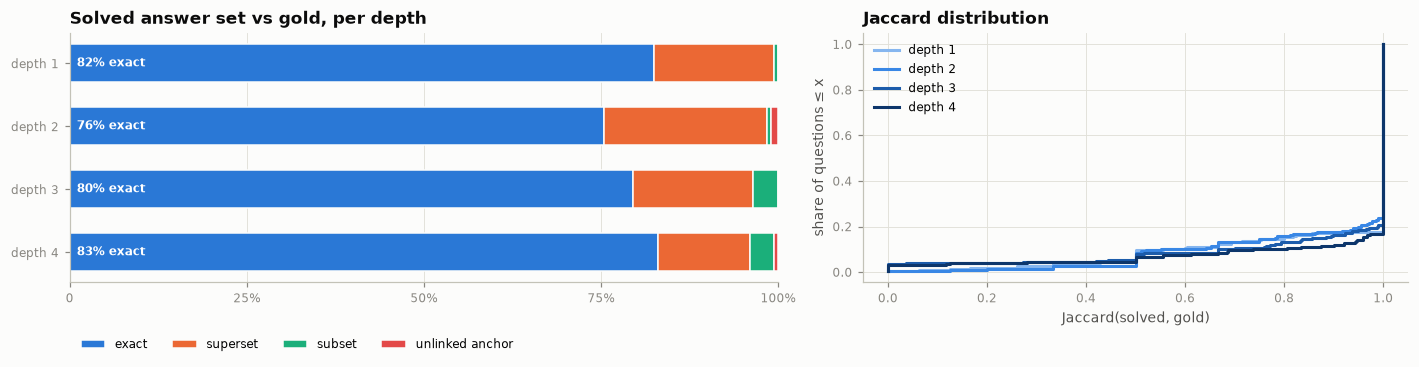

In [14]:
order = ["exact", "superset", "subset", "other", "unlinked anchor"]
cols = {"exact": C["blue"], "superset": C["orange"], "subset": C["aqua"], "other": C["other"], "unlinked anchor": C["red"]}
ct = pd.crosstab(R.depth, R.verdict, normalize="index").reindex(columns=order, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
left = np.zeros(len(ct))
for col in order:
    if ct[col].sum() == 0:
        continue
    axes[0].barh([f"depth {d}" for d in ct.index], ct[col], left=left, color=cols[col], height=0.6,
                 edgecolor=C["surface"], lw=1, label=col)
    left += ct[col].to_numpy()
for y, e in enumerate(ct["exact"]):
    axes[0].text(0.01, y, f"{e:.0%} exact", va="center", color="white", fontsize=8, fontweight="bold")
axes[0].invert_yaxis(); axes[0].set_xlim(0, 1); axes[0].grid(axis="y", visible=False)
axes[0].legend(ncol=5, loc="lower left", bbox_to_anchor=(0, -0.32))
axes[0].set_title("Solved answer set vs gold, per depth")
axes[0].set_xticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])

for d, col in zip(range(1, 5), SEQ):
    j = np.sort(R.jaccard[R.depth == d].dropna().to_numpy())
    axes[1].step(j, np.arange(1, len(j) + 1) / len(j), where="post", color=col, lw=2, label=f"depth {d}")
axes[1].set_xlabel("Jaccard(solved, gold)"); axes[1].set_ylabel("share of questions ≤ x")
axes[1].set_title("Jaccard distribution"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()

**Results.**
- **Recall is about 1.** The graph always contains the gold answers.
- **Errors are almost all supersets:** a few extra POIs just past a threshold, or anchors whose name belongs
  to several POIs.
- **Accuracy does not degrade with depth**, because each hop's relation is tolerant (≥ 100 m, usually 1 km).

**Remaining gaps.**
- The generator's exact rules (projection, tie-breaking) are unknown.
- Some seating values (`street`, `garden`, `summer`, …) never appear in the text.
- Ambiguous anchor names cannot be resolved from the text. The generator knew which POI it meant, so
  KGQA data built from this set should either disambiguate anchors (for example "Le Florida, Rue X") or drop
  those questions.

## 9. One question, step by step

A 3-hop question from the eval set, chosen with small answer sets and unique anchor names. The left panel
shows the question as a query graph: `?x1` is the innermost hop, the question asks for `?x3`, and grey nodes
are named entities from the tables. The right panel shows the same reasoning on the map.

In [15]:
def pick_example(depth=3, max_per_level=12):
    for qid in R.index[(R.depth == depth) & (R.verdict == "exact")]:
        lvl = K.parse_question(dump.query_texte[qid])
        levels = levels_cache[qid]
        anchors = [a for l in lvl.chain() for c in l.clauses for a in c.anchors if a != K.SUB]
        if all(1 <= len(x) <= max_per_level for x in levels) and len(levels[-1]) <= 3 and \
           all(len(kg.by_name.get(a, [])) <= 1 for a in anchors):
            return qid, lvl, levels
qid, q, levels = pick_example()
print(textwrap.fill(dump.loc[qid, "query"], 150))
for i, (l, rows) in enumerate(zip(q.chain(), levels), 1):
    print(f"\n?x{i} = {l.head}  ->  {len(rows)} POI(s): {', '.join(poi.poi_name.to_numpy()[rows][:8])}")
    for c in l.clauses:
        print("     ", c)
print("\ngold answers:", kg.names(dump.loc[qid, "answers"]))

Hotel without outdoor seating near cafe. Cafe at less than 300 meters from restaurant and following Rue du Faubourg Saint-Antoine and at less than 500
meters from Le Patio Bastille. Restaurant filipino food without outdoor seating near Le Soleil Levant and between Le BizArt and Once Coktail bar and
near Patrick’s Ballon Vert towards Impronta.

?x1 = restaurant filipino food without outdoor seating  ->  1 POI(s): Reyna
      near: Le Soleil Levant
      between: Le BizArt | Once Coktail bar
      near_towards: Patrick’s Ballon Vert | Impronta

?x2 = cafe  ->  10 POI(s): Le Virginie, La Liberté, Café Pivoine, La Parisienne du Faubourg, Bistrot Café de Paris, Le Bidule, La Poulette de Grain, Space 21
      within(300): <SUB>
      following: Rue du Faubourg Saint-Antoine
      within(500): Le Patio Bastille

?x3 = hotel without outdoor seating  ->  1 POI(s): ibis Styles Paris Gare de Lyon TGV
      near: <SUB>

gold answers: ['ibis Styles Paris Gare de Lyon TGV']


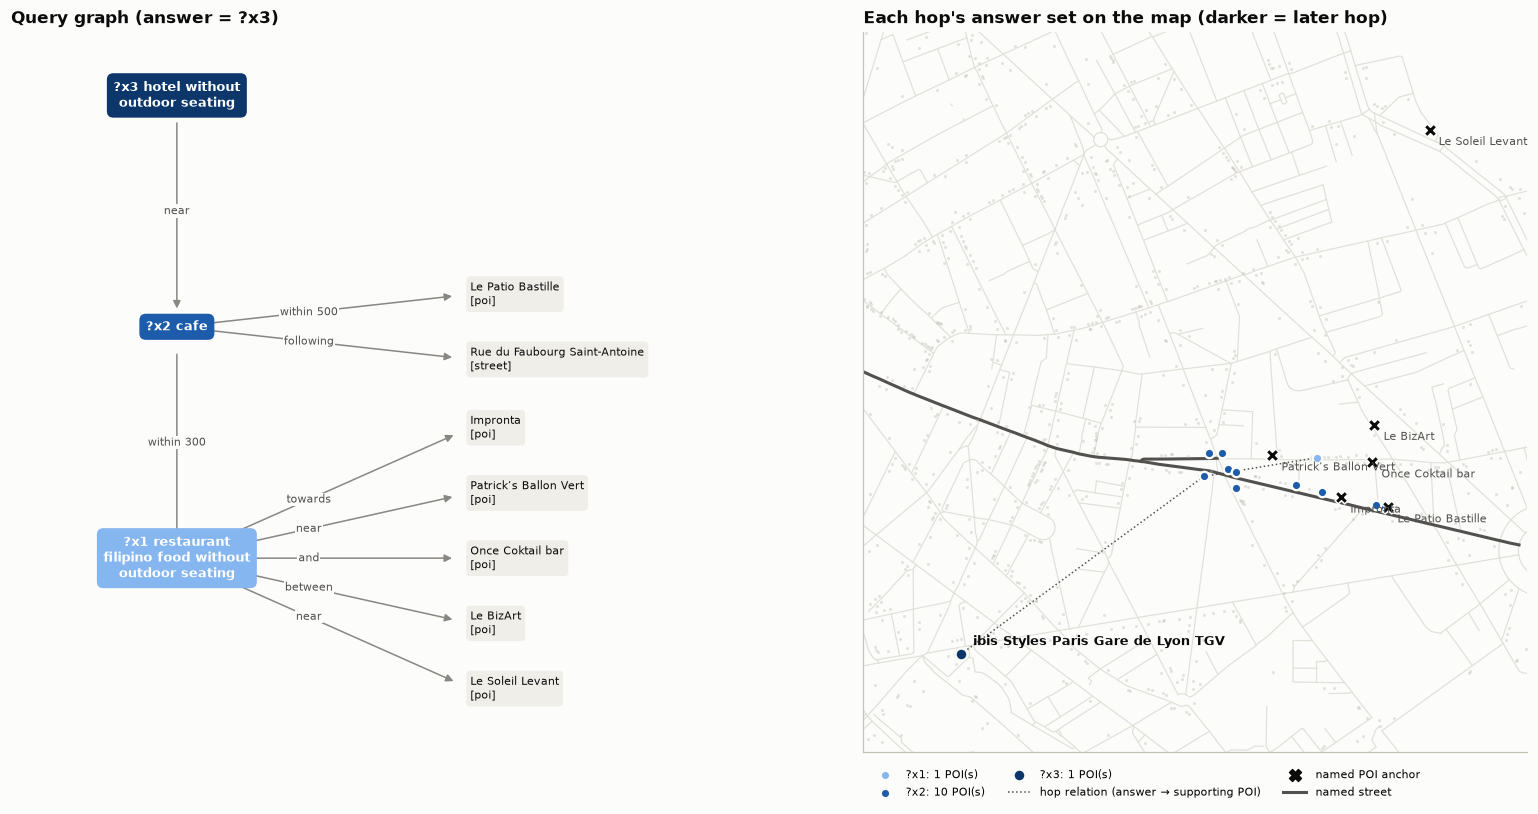

In [16]:
G = K.query_graph(q)
fig, (axg, axm) = plt.subplots(1, 2, figsize=(15, 7.5), gridspec_kw=dict(width_ratios=[1, 1.15]))

# --- query graph: variables on a vertical spine (innermost at the bottom), anchors fanned out to the right
pos = {}
nvar = q.depth
hop_cols = [SEQ[int(i)] for i in np.linspace(0, 3, nvar).round()]  # spread the ordinal ramp over the hops
for n, d in G.nodes(data=True):
    if d["kind"] == "variable":
        pos[n] = (0, d["level"] * 2.2)
by_level = collections.defaultdict(list)
for n, d in G.nodes(data=True):
    if d["kind"] != "variable":
        by_level[d["level"]].append(n)
for lv, ns in by_level.items():
    for k, n in enumerate(ns):
        pos[n] = (2.3, lv * 2.2 + (k - (len(ns) - 1) / 2) * 0.62)
kind_col = {"variable": SEQ, "poi": C["other"], "street": C["other"], "area": C["other"]}
for u, v, d in G.edges(data=True):
    (x0, y0), (x1, y1) = pos[u], pos[v]
    axg.annotate("", xy=(x1, y1), xytext=(x0, y0),
                 arrowprops=dict(arrowstyle="-|>", color=C["muted"], lw=1, shrinkA=18, shrinkB=12))
    t = 0.5 if G.nodes[v]["kind"] == "variable" else 0.45
    axg.text(x0 + (x1 - x0) * t, y0 + (y1 - y0) * t, d["label"], fontsize=7.5, color=C["ink2"], ha="center",
             va="center", bbox=dict(fc=C["surface"], ec="none", pad=0.6))
for n, d in G.nodes(data=True):
    x, y = pos[n]
    if d["kind"] == "variable":
        col = hop_cols[d["level"] - 1]
        axg.text(x, y, textwrap.fill(d["label"], 22), ha="center", va="center", fontsize=8.5, color="white",
                 fontweight="bold", bbox=dict(boxstyle="round,pad=0.5", fc=col, ec="none"))
    else:
        axg.text(x, y, f"{textwrap.shorten(n, 30)}\n[{d['kind']}]", ha="left", va="center", fontsize=7.5,
                 color=C["ink"], bbox=dict(boxstyle="round,pad=0.35", fc="#efeee9", ec="none"))
ys = [y for _, y in pos.values()]
axg.set_xlim(-1.3, 4.6); axg.set_ylim(min(ys) - 0.6, max(ys) + 0.6); axg.axis("off")
axg.set_title("Query graph (answer = ?x%d)" % nvar)

# --- map: every hop's answer set + the named anchors
all_rows = np.concatenate(levels)
anchor_pts = {}
for l in q.chain():
    for c in l.clauses:
        for a in c.anchors:
            if a in kg.by_name and K.RELATION_ANCHOR[c.kind] == "poi":
                anchor_pts[a] = kg.xy[kg.by_name[a][0]]
pts = np.vstack([kg.xy[all_rows]] + list(anchor_pts.values()))
lo, hi = pts.min(0) - 250, pts.max(0) + 250
box = lambda P: ((P >= lo) & (P <= hi)).all(-1)
for lines in kg.street_lines.values():
    for line in lines:
        if box(line).any():
            axm.plot(*line.T, color=C["grid"], lw=0.8, zorder=1)
for l in q.chain():                                   # highlight named streets / areas
    for c in l.clauses:
        if c.kind in ("following", "intersection"):
            for s in c.anchors:
                for line in kg.street_lines[s]:
                    axm.plot(*line.T, color=C["ink2"], lw=2, zorder=2)
        if c.kind in ("inside", "border", "dir_in_area"):
            for rings in K.polygons(kg.area_geom[c.anchors[0]]):
                axm.plot(*rings[0].T, color=C["ink2"], lw=1.5, ls="--", zorder=2)
bg = box(kg.xy)
axm.scatter(*kg.xy[bg].T, s=4, color=C["other"], alpha=0.35, lw=0, zorder=2)
for i, (rows, col) in enumerate(zip(levels, hop_cols), 1):
    axm.scatter(*kg.xy[rows].T, s=60 if i == nvar else 38, color=col, edgecolor=C["surface"], lw=1.5, zorder=4 + i,
                label=f"?x{i}: {len(rows)} POI(s)")
path = K.support_path(kg, levels)                     # which POI of hop i-1 supports each POI of hop i
for prev, cur in zip(path[:-1], path[1:]):
    for r in cur:
        j = prev[np.argmin(np.linalg.norm(kg.xy[prev] - kg.xy[r], axis=1))]
        axm.plot(*np.stack([kg.xy[r], kg.xy[j]]).T, color=C["ink2"], lw=1, ls=":", zorder=3)
axm.plot([], [], color=C["ink2"], lw=1, ls=":", label="hop relation (answer → supporting POI)")
for r in levels[-1]:
    axm.annotate(poi.poi_name.to_numpy()[r], kg.xy[r], xytext=(8, 6), textcoords="offset points",
                 fontsize=8.5, fontweight="bold", color=C["ink"], zorder=10)
for a, p in anchor_pts.items():
    axm.scatter(*p, marker="X", s=70, color=C["ink"], edgecolor=C["surface"], lw=1, zorder=9)
    axm.annotate(textwrap.shorten(a, 26), p, xytext=(6, -10), textcoords="offset points", fontsize=7.5,
                 color=C["ink2"], zorder=10)
axm.scatter([], [], marker="X", s=60, color=C["ink"], label="named POI anchor")
axm.plot([], [], color=C["ink2"], lw=2, label="named street")
axm.set_xlim(lo[0], hi[0]); axm.set_ylim(lo[1], hi[1]); axm.set_aspect("equal")
axm.set_xticks([]); axm.set_yticks([]); axm.grid(False)
axm.legend(loc="upper left", bbox_to_anchor=(0, -0.01), ncol=3, fontsize=7.5)
axm.set_title("Each hop's answer set on the map (darker = later hop)")
plt.tight_layout(); plt.show()

## 10. Proposed KGQA sample format

Like the GraphQA, MetaQA and KQA Pro setups, each sample has three parts:
1. **Question:** the nested `query_texte` or the flattened `description_textuelle`.
2. **Context subgraph** in the prompt: the facts needed to answer.
   - *Gold-path context:* only the facts on the reasoning path, as below.
   - *Retrieved context:* all POIs within ~1 km of the named anchors, with their relations. This is the
     harder, realistic variant.
3. **Answer:** the POI names. Answer sets need a cap. 72% of 1-hop questions have exactly one answer and 97%
   have ≤ 10. At depths 2–4, 38–43% have exactly one answer and 75–77% have ≤ 10 (§4).

A gold-path serialisation of the example above:

In [17]:
def serialise(q, levels):
    # gold-path context: only the POIs on the reasoning path to the final answers (osm_kg.support_path)
    names, facts = poi.poi_name.to_numpy(), []
    path = K.support_path(kg, levels)
    for i, (l, rows) in enumerate(zip(q.chain(), path), 1):
        for r in rows:
            p = poi.iloc[r]
            facts.append(f"({names[r]}; " + ", ".join(f"{k}={p[k]}" for k in l.attrs) + ")")
            for c in l.clauses:
                rel = c.kind + (f" {c.param}" if c.param is not None else "")
                if K.SUB in c.anchors:
                    prev = path[i - 2]
                    j = prev[np.argmin(np.linalg.norm(kg.xy[prev] - kg.xy[r], axis=1))]
                    d = np.linalg.norm(kg.xy[j] - kg.xy[r])
                    facts.append(f"({names[r]}; {rel}; {names[j]})   # {d:.0f} m")
                else:
                    facts.append(f"({names[r]}; {rel}; {' / '.join(c.anchors)})")
    return facts

print("Question:", textwrap.fill(dump.loc[qid, "query"], 140), "\n")
print("Context:"); print("\n".join(serialise(q, levels)))
print("\nAnswer:", " | ".join(kg.names(dump.loc[qid, "answers"])))

Question: Hotel without outdoor seating near cafe. Cafe at less than 300 meters from restaurant and following Rue du Faubourg Saint-Antoine and at
less than 500 meters from Le Patio Bastille. Restaurant filipino food without outdoor seating near Le Soleil Levant and between Le BizArt
and Once Coktail bar and near Patrick’s Ballon Vert towards Impronta. 

Context:
(Reyna; category=restaurant, cooking_type=filipino, outdoor_seating=no)
(Reyna; near; Le Soleil Levant)
(Reyna; between; Le BizArt / Once Coktail bar)
(Reyna; near_towards; Patrick’s Ballon Vert / Impronta)
(La Liberté; category=cafe)
(La Liberté; within 300; Reyna)   # 294 m
(La Liberté; following; Rue du Faubourg Saint-Antoine)
(La Liberté; within 500; Le Patio Bastille)
(ibis Styles Paris Gare de Lyon TGV; category=hotel, outdoor_seating=no)
(ibis Styles Paris Gare de Lyon TGV; near; La Liberté)   # 773 m

Answer: ibis Styles Paris Gare de Lyon TGV


## 11. A built KGQA sample as a graph

The §9 question is in the built test split (`data/osm/kgqa/test.jsonl`, qid 639761). The figure is drawn from the
**prompt only**: the fact lines are parsed back into a graph, and each entity is checked against its hop.
- **Panels:** one per hop, with the final hop on top. Each hop's entities are on the left. On the right are the
  named anchors they point to (labelled *relation → name*) and the previous hop's entities, reached through the
  hop relation.
- **Valid entities** (blue) form the reasoning path to the answer.
- **Distractors** (orange outline) are labelled with the fact they lack. Example: Mémère Louise is a cafe on Rue
  du Faubourg Saint-Antoine near Le Patio Bastille, but it is not within 300 m of any valid ?x1. Only the inner
  hop rules it out.

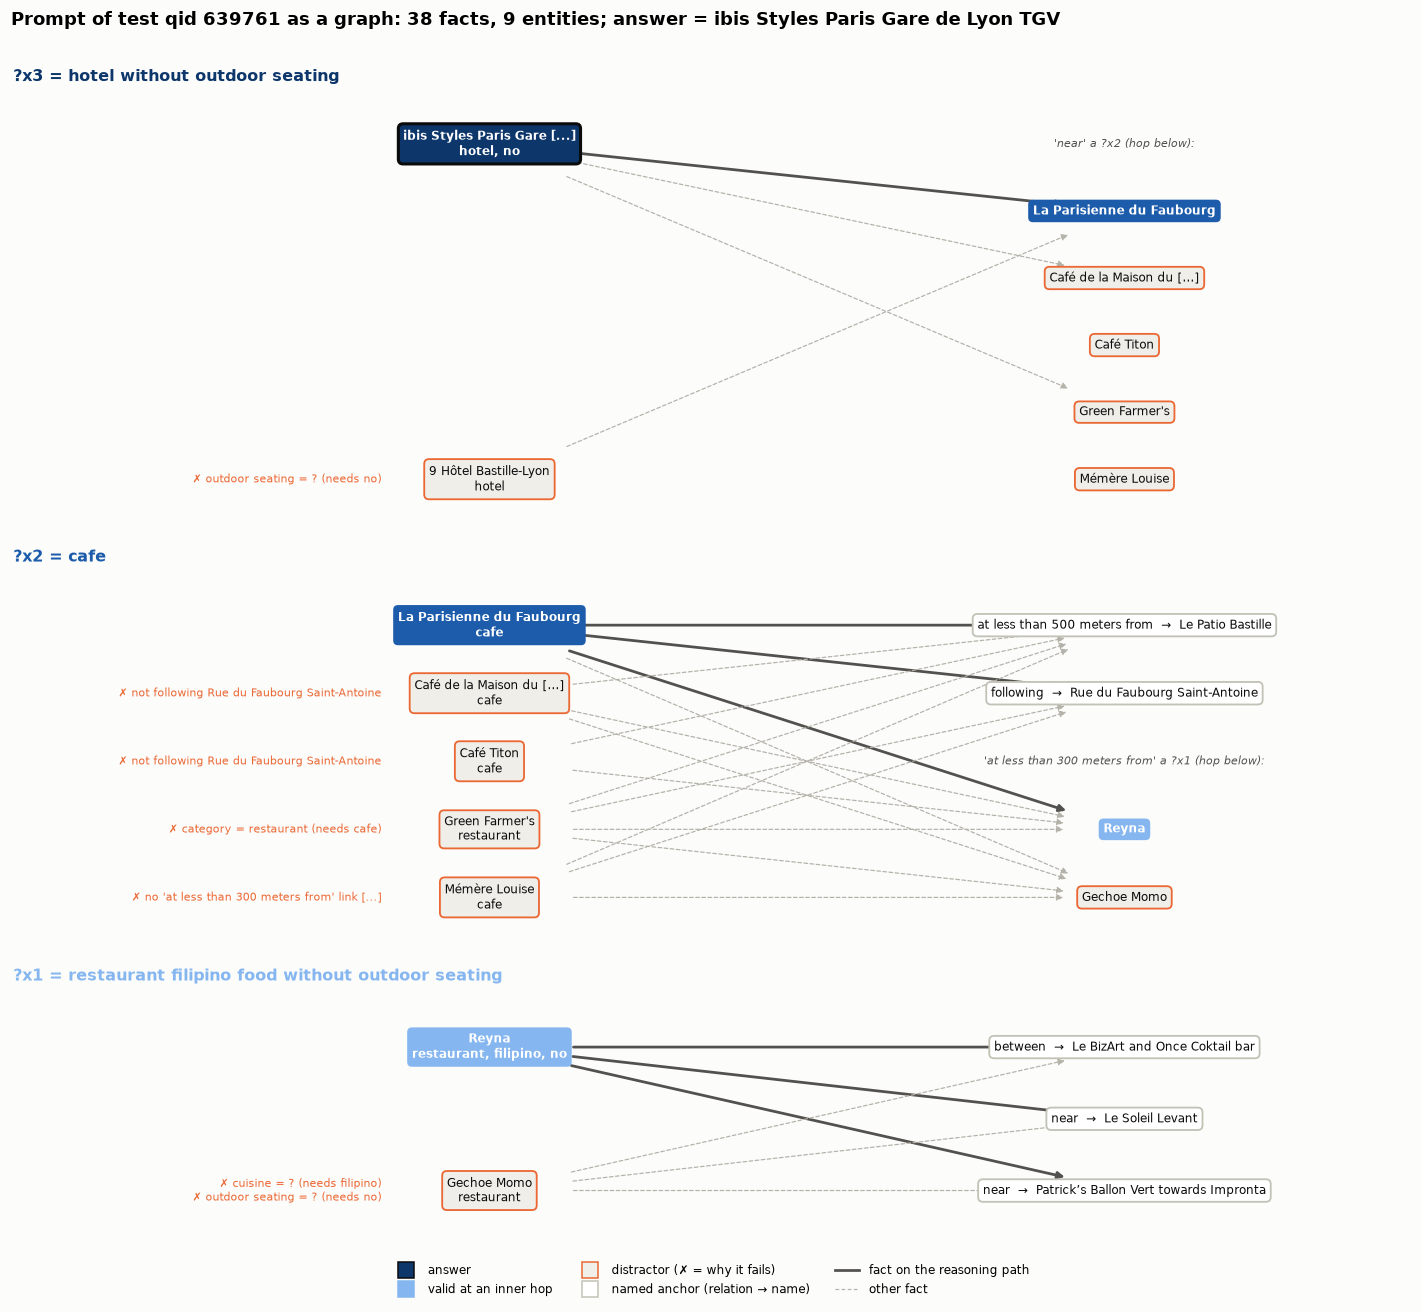

In [18]:
import json, re, collections, textwrap
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch

sys.path.insert(0, str(Path.cwd().parent / "scripts" / "osm"))
from check_kgqa import FACT
from build_kgqa import ATTR_LABEL, phrase

KGQA_DIR = Path.cwd().parent / "data" / "osm" / "kgqa"
test = [json.loads(l) for l in open(KGQA_DIR / "test.jsonl")]
rec = next(r for r in test if r["qid"] == 639761)  # the §9 question, as built in the test split


def prompt_graph(rec):
    # Parse a KGQA prompt back into entities, facts and per-hop roles (valid / distractor + why it fails).
    body = rec["instruction"].split("The facts are:\n", 1)[1].split("\nQ: ")[0]
    facts = collections.defaultdict(set)
    for line in body.split("\n"):
        s, p, o = FACT.match(line).groups()
        facts[s].add((p, o))
    chain = K.parse_question(rec["question"]).chain()
    attr_rels = set(ATTR_LABEL.values())

    def score(ent, lvl):  # how much of hop `lvl` the entity's facts cover
        fs = facts[ent]
        a = sum((ATTR_LABEL[k], v.replace("_", " ")) in fs for k, v in lvl.attrs.items())
        c = sum(any(f[0] == phrase(cl, "_")[0] for f in fs) if K.SUB in cl.anchors else phrase(cl) in fs
                for cl in lvl.clauses)
        return a + c

    hop_of = {e: max(range(len(chain)), key=lambda i: (score(e, chain[i]), -i)) for e in facts}
    valid, why = [set() for _ in chain], {}
    for i, lvl in enumerate(chain):
        for e in [e for e, h in hop_of.items() if h == i]:
            fs, miss = facts[e], []
            for k, v in lvl.attrs.items():
                if (ATTR_LABEL[k], v.replace("_", " ")) not in fs:
                    have = [o for p, o in fs if p == ATTR_LABEL[k]]
                    miss.append(f"{ATTR_LABEL[k]} = {have[0] if have else '?'} (needs {v.replace('_', ' ')})")
            for cl in lvl.clauses:
                if K.SUB in cl.anchors:
                    rel = phrase(cl, "_")[0]
                    if not any((rel, q) in fs for q in valid[i - 1]):
                        miss.append(f"no '{rel}' link to a valid ?x{i}")
                elif phrase(cl) not in fs:
                    miss.append("not " + " ".join(phrase(cl)))
            if miss:
                why[e] = miss
            else:
                valid[i].add(e)
    anchors = sorted({o for e, fs in facts.items() for p, o in fs if p not in attr_rels and o not in facts})
    return facts, chain, hop_of, valid, why, anchors


facts, chain, hop_of, valid, why, anchors = prompt_graph(rec)
assert sorted(valid[-1], key=str.lower) == rec["answers"]

# ---- one panel per hop (final hop on top): hop entities on the left, what they point to on the right
nhop = len(chain)
hop_cols = [SEQ[int(i)] for i in np.linspace(0, 3, nhop).round()]
rel_of = {o: p for fs in facts.values() for p, o in fs if o in anchors}
ents = {i: sorted([e for e, h in hop_of.items() if h == i], key=lambda e: (e not in valid[i], e.lower()))
        for i in range(nhop)}


def targets(i):
    own = sorted({o for e in ents[i] for p, o in facts[e] if o in anchors})
    prev = ents[i - 1] if i else []
    return own, prev


heights = [max(len(ents[i]), sum(map(len, targets(i))) + (1 if i else 0)) + 1.2 for i in reversed(range(nhop))]
fig, axes = plt.subplots(nhop, 1, figsize=(13, 0.62 * sum(heights) + 1.2), gridspec_kw=dict(height_ratios=heights))


def node(ax, x, y, text, fc, ec="none", lw=1.2, color="white", bold=True, ha="center"):
    ax.text(x, y, text, ha=ha, va="center", fontsize=7.8, color=color, fontweight="bold" if bold else "normal",
            zorder=4, bbox=dict(boxstyle="round,pad=0.4", fc=fc, ec=ec, lw=lw))


for ax, i in zip(axes, reversed(range(nhop))):
    own, prev = targets(i)
    H = max(len(ents[i]), len(own) + len(prev) + (1 if prev else 0))
    ys = lambda n: np.linspace(H - 1, 0, n) if n > 1 else np.array([(H - 1) / 2])  # noqa: E731
    pe = {e: (0.0, y) for e, y in zip(ents[i], ys(len(ents[i])))}
    tys = ys(len(own) + len(prev) + (1 if prev else 0))
    pt = {a: (1.0, y) for a, y in zip(own, tys[:len(own)])}
    pt.update({e: (1.0, y) for e, y in zip(prev, tys[len(own) + 1:])})
    for e in ents[i]:
        for p, o in facts[e]:
            if o in pt:
                good = e in valid[i] and (o not in prev or o in valid[i - 1])
                ax.add_patch(FancyArrowPatch(pe[e], pt[o], arrowstyle="-|>", mutation_scale=9, zorder=1,
                                             shrinkA=55, shrinkB=40, lw=1.8 if good else 0.8,
                                             color=C["ink2"] if good else C["other"], ls="-" if good else (0, (3, 2))))
    for e, (x, y) in pe.items():
        ok = e in valid[i]
        attrs = ", ".join(o for p, o in sorted(facts[e]) if p in ATTR_LABEL.values())
        node(ax, x, y, f"{textwrap.shorten(e, 30)}\n{attrs}", hop_cols[i] if ok else "#efeee9",
             ec=("#0b0b0b" if i == nhop - 1 else "none") if ok else C["orange"], lw=2 if ok else 1.2,
             color="white" if ok else C["ink"], bold=ok)
        if not ok:
            ax.text(x - 0.17, y, "\n".join("✗ " + textwrap.shorten(m, 46) for m in why[e]), ha="right",
                    va="center", fontsize=7, color=C["orange"])
    for a in own:
        x, y = pt[a]
        node(ax, x, y, f"{rel_of[a]}  →  {textwrap.shorten(a, 40)}", "white", ec=C["axis"], color=C["ink"],
             bold=False)
    if prev:
        hop_rel = next(phrase(c, "_")[0] for c in chain[i].clauses if K.SUB in c.anchors)
        ax.text(1.0, tys[len(own)], f"'{hop_rel}' a ?x{i} (hop below):", ha="center", va="center", fontsize=7.5,
                style="italic", color=C["ink2"])
        for e in prev:
            ok = e in valid[i - 1]
            node(ax, *pt[e], textwrap.shorten(e, 30), hop_cols[i - 1] if ok else "#efeee9",
                 ec="none" if ok else C["orange"], color="white" if ok else C["ink"], bold=ok)
    ax.set_xlim(-0.75, 1.45)
    ax.set_ylim(-0.8, H - 0.2)
    ax.axis("off")
    ax.set_title(f"?x{i + 1} = {chain[i].head}", color=hop_cols[i], loc="left", fontsize=10.5)

axes[-1].legend(handles=[
    Line2D([], [], marker="s", ls="", ms=10, color=hop_cols[-1], mec="#0b0b0b", label="answer"),
    Line2D([], [], marker="s", ls="", ms=10, color=hop_cols[0], label="valid at an inner hop"),
    Line2D([], [], marker="s", ls="", ms=10, color="#efeee9", mec=C["orange"], label="distractor (✗ = why it fails)"),
    Line2D([], [], marker="s", ls="", ms=10, color="white", mec=C["axis"], label="named anchor (relation → name)"),
    Line2D([], [], color=C["ink2"], lw=1.8, label="fact on the reasoning path"),
    Line2D([], [], color=C["other"], lw=0.8, ls=(0, (3, 2)), label="other fact"),
], loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=8)
fig.suptitle(f"Prompt of test qid {rec['qid']} as a graph: {rec['n_facts']} facts, {len(facts)} entities; "
             f"answer = {' | '.join(rec['answers'])}", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.975))
plt.show()

## 12. Do the multi-hop questions really need their inner hops?

**The shortcut.** It checks only the outermost hop. A candidate passes if:
- its attributes match, and
- its named-anchor conditions hold, and
- it has *a* link of the right relation type to the previous hop, whether or not the linked entity is itself valid.

If the shortcut's answer equals the true answer, the inner hops did not matter for that question.
`check_kgqa.py` reports that this happens for 40–56% of the 2–4-hop test questions.

**Two 3-hop test questions,** drawn as one chain with each entity once:
- Columns are hops: ?x1 on the left, the answer on the right.
- Each box lists the entity's conditions (✓ / ✗), including the hop link ("✓ near valid ?x2" or "✗ … only
  INVALID ?x2").
- Arrows are hop facts.

**Left: the §9/§11 question.** The shortcut is right. The only other hotel already fails an attribute
(outdoor seating), so the answer can be found from the last column alone, without looking at the chain.

**Right: a question where the shortcut is wrong.** Ambroise Paré meets every condition of its own hop and has a
"to the west of" link. But that link goes to Pondichery, which is not a valid ?x2 (cuisine is not noodle). Only
following the chain back shows that Ambroise Paré is not an answer.

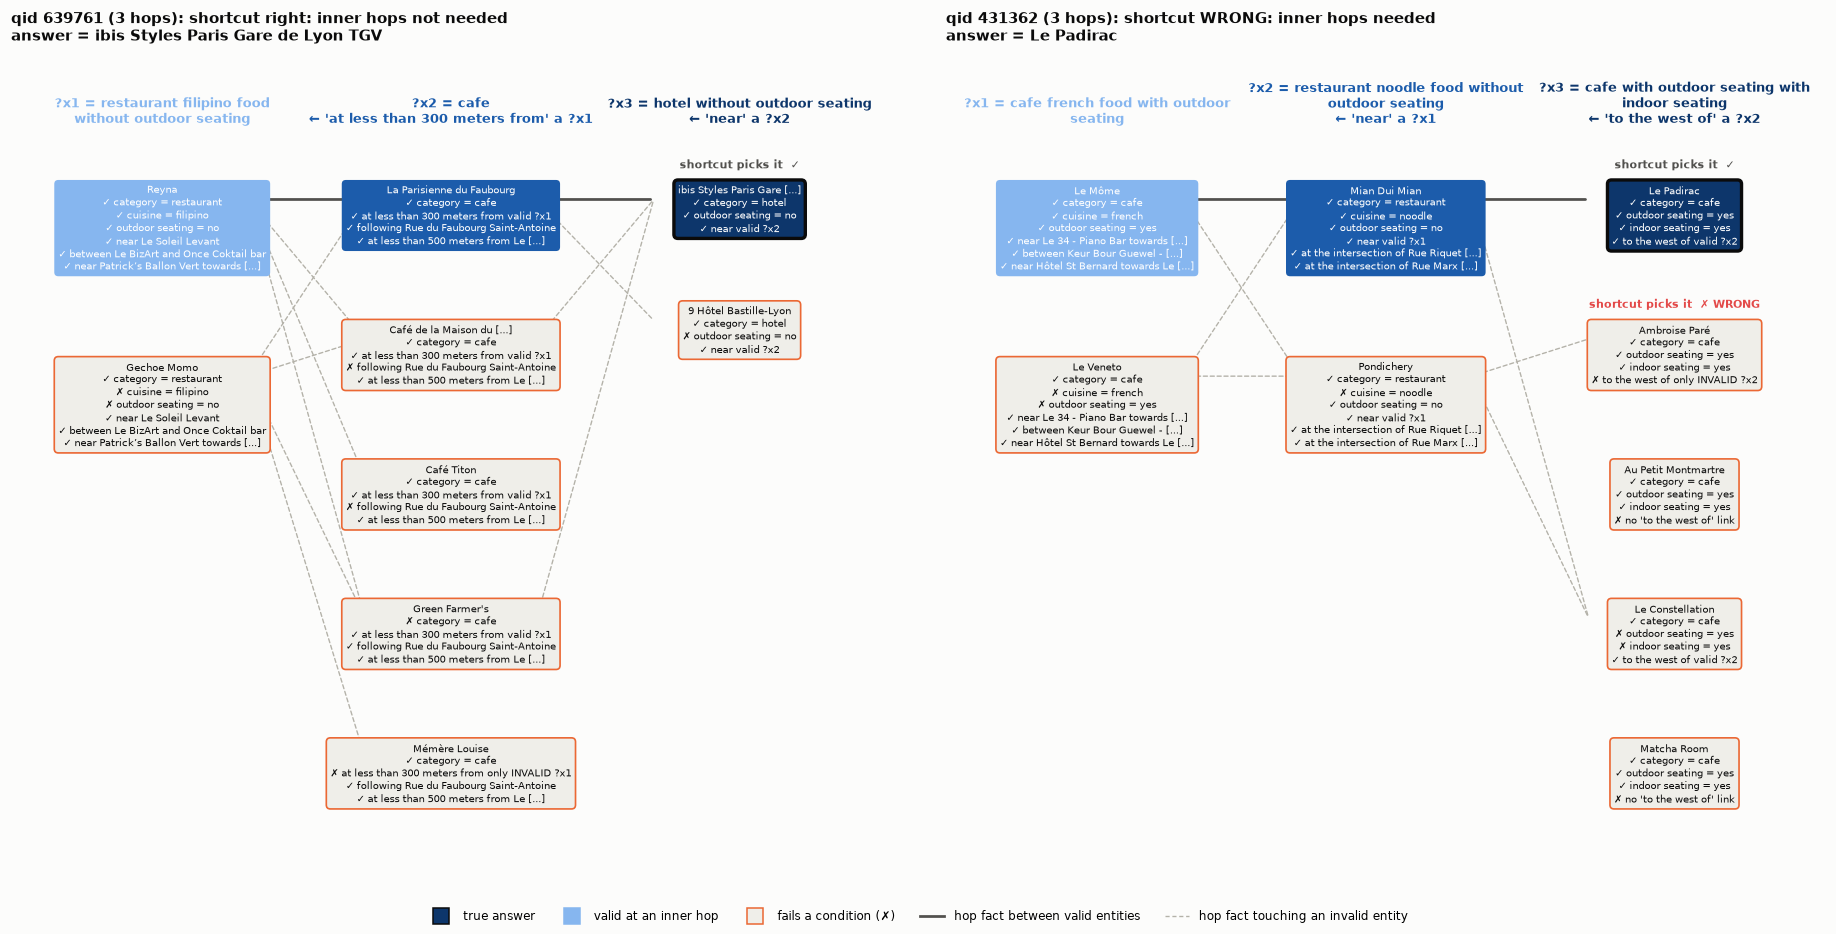

In [19]:
from check_kgqa import solve_from_prompt

def needs_inner_hops(rec):
    # True when checking only the outer hop (any link of the right relation counts) gives a wrong answer
    return solve_from_prompt(rec, shortcut=True) != rec["answers"]


def chain_view(rec, ax):
    # One node per entity, one column per hop (?x1 left ... answer right). Each box lists the entity's own-hop
    # conditions (✓ / ✗); arrows are hop facts pointing to the previous hop's entities.
    facts, chain, hop_of, valid, why, anchors = prompt_graph(rec)
    nhop = len(chain)
    cols = [SEQ[int(i)] for i in np.linspace(0, 3, nhop).round()]
    short = set(solve_from_prompt(rec, shortcut=True))
    pos, box_h = {}, {}
    for i in range(nhop):
        ents = sorted([e for e, h in hop_of.items() if h == i], key=lambda e: (e not in valid[i], e.lower()))
        y = 0.0
        for e in ents:
            lines = []
            fs = facts[e]
            for k, v in chain[i].attrs.items():
                ok = (ATTR_LABEL[k], v.replace("_", " ")) in fs
                lines.append(("✓ " if ok else "✗ ") + f"{ATTR_LABEL[k]} = {v.replace('_', ' ')}")
            for c in chain[i].clauses:
                if K.SUB in c.anchors:  # the hop condition: a link to a *valid* entity of the previous hop
                    rel = phrase(c, "_")[0]
                    linked = [q for q in valid[i - 1] if (rel, q) in fs]
                    any_link = any(p == rel for p, _ in fs)
                    lines.append(f"✓ {rel} valid ?x{i}" if linked else
                                 (f"✗ {rel} only INVALID ?x{i}" if any_link else f"✗ no '{rel}' link"))
                    continue
                ok = phrase(c) in fs
                lines.append(("✓ " if ok else "✗ ") + textwrap.shorten(" ".join(phrase(c)), 40))
            box_h[e] = len(lines) + 1
            pos[e] = (i * 4.2, -y)
            y += box_h[e] * 0.36 + 0.9
            ok = e in valid[i]
            final = i == nhop - 1
            ax.text(*pos[e], f"{textwrap.shorten(e, 28)}\n" + "\n".join(lines), ha="center", va="top", fontsize=6.6,
                    color="white" if ok else C["ink"], zorder=4, linespacing=1.25,
                    bbox=dict(boxstyle="round,pad=0.4", fc=cols[i] if ok else "#efeee9",
                              ec="#0b0b0b" if (ok and final) else (C["orange"] if not ok else "none"),
                              lw=2.2 if (ok and final) else 1.1))
            if final and e in short:
                tag, colr = ("shortcut picks it  ✓", C["ink2"]) if ok else ("shortcut picks it  ✗ WRONG", C["red"])
                ax.text(pos[e][0], pos[e][1] + 0.25, tag, ha="center", va="bottom", fontsize=7.5, fontweight="bold",
                        color=colr)
    for e, fs in facts.items():
        for p, o in fs:
            if o in pos and hop_of.get(o, -1) == hop_of[e] - 1:
                good = e in valid[hop_of[e]] and o in valid[hop_of[o]]
                (x0, y0), (x1, y1) = pos[e], pos[o]
                ax.add_patch(FancyArrowPatch((x0 - 1.25, y0 - 0.3), (x1 + 1.25, y1 - 0.3), arrowstyle="-|>",
                                             mutation_scale=9, lw=1.8 if good else 0.9, zorder=1,
                                             color=C["ink2"] if good else C["other"], ls="-" if good else (0, (3, 2))))
    for i, lvl in enumerate(chain):
        hop = next((phrase(c, "_")[0] for c in lvl.clauses if K.SUB in c.anchors), None)
        head = f"?x{i + 1} = {textwrap.fill(lvl.head, 30)}" + (f"\n← '{hop}' a ?x{i}" if hop else "")
        ax.text(i * 4.2, 1.1, head, ha="center", va="bottom", fontsize=8.3, fontweight="bold", color=cols[i])
    ymin = min(y - box_h[e] * 0.36 for e, (_, y) in pos.items())
    ax.set_xlim(-2.2, (nhop - 1) * 4.2 + 2.2)
    ax.set_ylim(ymin - 0.6, 2.6)
    ax.axis("off")
    verdict = "shortcut WRONG: inner hops needed" if needs_inner_hops(rec) else "shortcut right: inner hops not needed"
    ax.set_title(f"qid {rec['qid']} ({rec['depth']} hops): {verdict}\nanswer = {' | '.join(rec['answers'])}",
                 fontsize=9.5, loc="left")


# Example A = the §9/§11 question; example B = a 3-hop test question the shortcut gets wrong (smallest prompt)
ex_a = rec
ex_b = min((r for r in test if r["depth"] == 3 and needs_inner_hops(r) and len(r["answers"]) == 1),
           key=lambda r: r["n_entities"])
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))
chain_view(ex_a, axes[0])
chain_view(ex_b, axes[1])
fig.legend(handles=[
    Line2D([], [], marker="s", ls="", ms=10, color=SEQ[-1], mec="#0b0b0b", label="true answer"),
    Line2D([], [], marker="s", ls="", ms=10, color=SEQ[0], label="valid at an inner hop"),
    Line2D([], [], marker="s", ls="", ms=10, color="#efeee9", mec=C["orange"], label="fails a condition (✗)"),
    Line2D([], [], color=C["ink2"], lw=1.8, label="hop fact between valid entities"),
    Line2D([], [], color=C["other"], lw=0.9, ls=(0, (3, 2)), label="hop fact touching an invalid entity"),
], loc="lower center", ncol=5, fontsize=8)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

**Two ways to fix it.** The table below counts the built 2–4-hop rows by whether the shortcut fails on them
(`needs_inner_hops`).
- **Fix 1, filter.** Keep only `needs_inner_hops` rows at depths 2–4 (the right-hand kind). Every multi-hop
  question then requires the chain. The cost is about half the multi-hop candidates. There are enough left to
  fill the quotas, so the build would sample more instead of shrinking.
- **Fix 2, tag.** Keep every row, store `needs_inner_hops` as a field, and report two test scores: on all rows,
  and on the `needs_inner_hops` subset. The data stays as it is, and the subset score shows whether a model
  really follows the chain.

In [20]:
rows = []
for split in ("train", "val", "test"):
    for r in (json.loads(l) for l in open(KGQA_DIR / f"{split}.jsonl")):
        rows.append(dict(split=split, depth=r["depth"], needs_inner_hops=needs_inner_hops(r)))
H = pd.DataFrame(rows)
H = H[H.depth > 1]
tab = H.groupby(["split", "depth"]).needs_inner_hops.agg(rows="size", needs_inner="sum")
tab["share"] = (tab.needs_inner / tab.rows).round(3)
tab["fix 1: rows kept (filter)"] = tab.needs_inner
tab["fix 2: rows kept (tag + 2 scores)"] = tab.rows
tab

rows  needs_inner  share  fix 1: rows kept (filter)  fix 2: rows kept (tag + 2 scores)
split depth                                                                                        
test  2       500          218  0.436                        218                                500
      3       500          298  0.596                        298                                500
      4       500          275  0.550                        275                                500
train 2      5000         2660  0.532                       2660                               5000
      3      5000         3124  0.625                       3124                               5000
      4      5000         2822  0.564                       2822                               5000
val   2       250          124  0.496                        124                                250
      3       250          153  0.612                        153                                250
      4       250          135  0.540                        135                                250

## 13. The same prompt as one graph

This is the §11 sample (test qid 639761) on a single canvas: every entity and anchor appears once, and every
relation fact is one edge.
- **Columns** are hops: ?x1 on the left, the answer on the right. Each hop's named anchors sit above its column,
  with the relation on top of the name.
- **Solid, labelled edges** are the reasoning path: Reyna → La Parisienne du Faubourg → ibis Styles. The
  horizontal arcs are the hop facts.
- **Dashed edges** are the other facts in the prompt, mostly the distractors' links.
- Each distractor shows its first failure (✗). §11 lists all of them hop by hop.

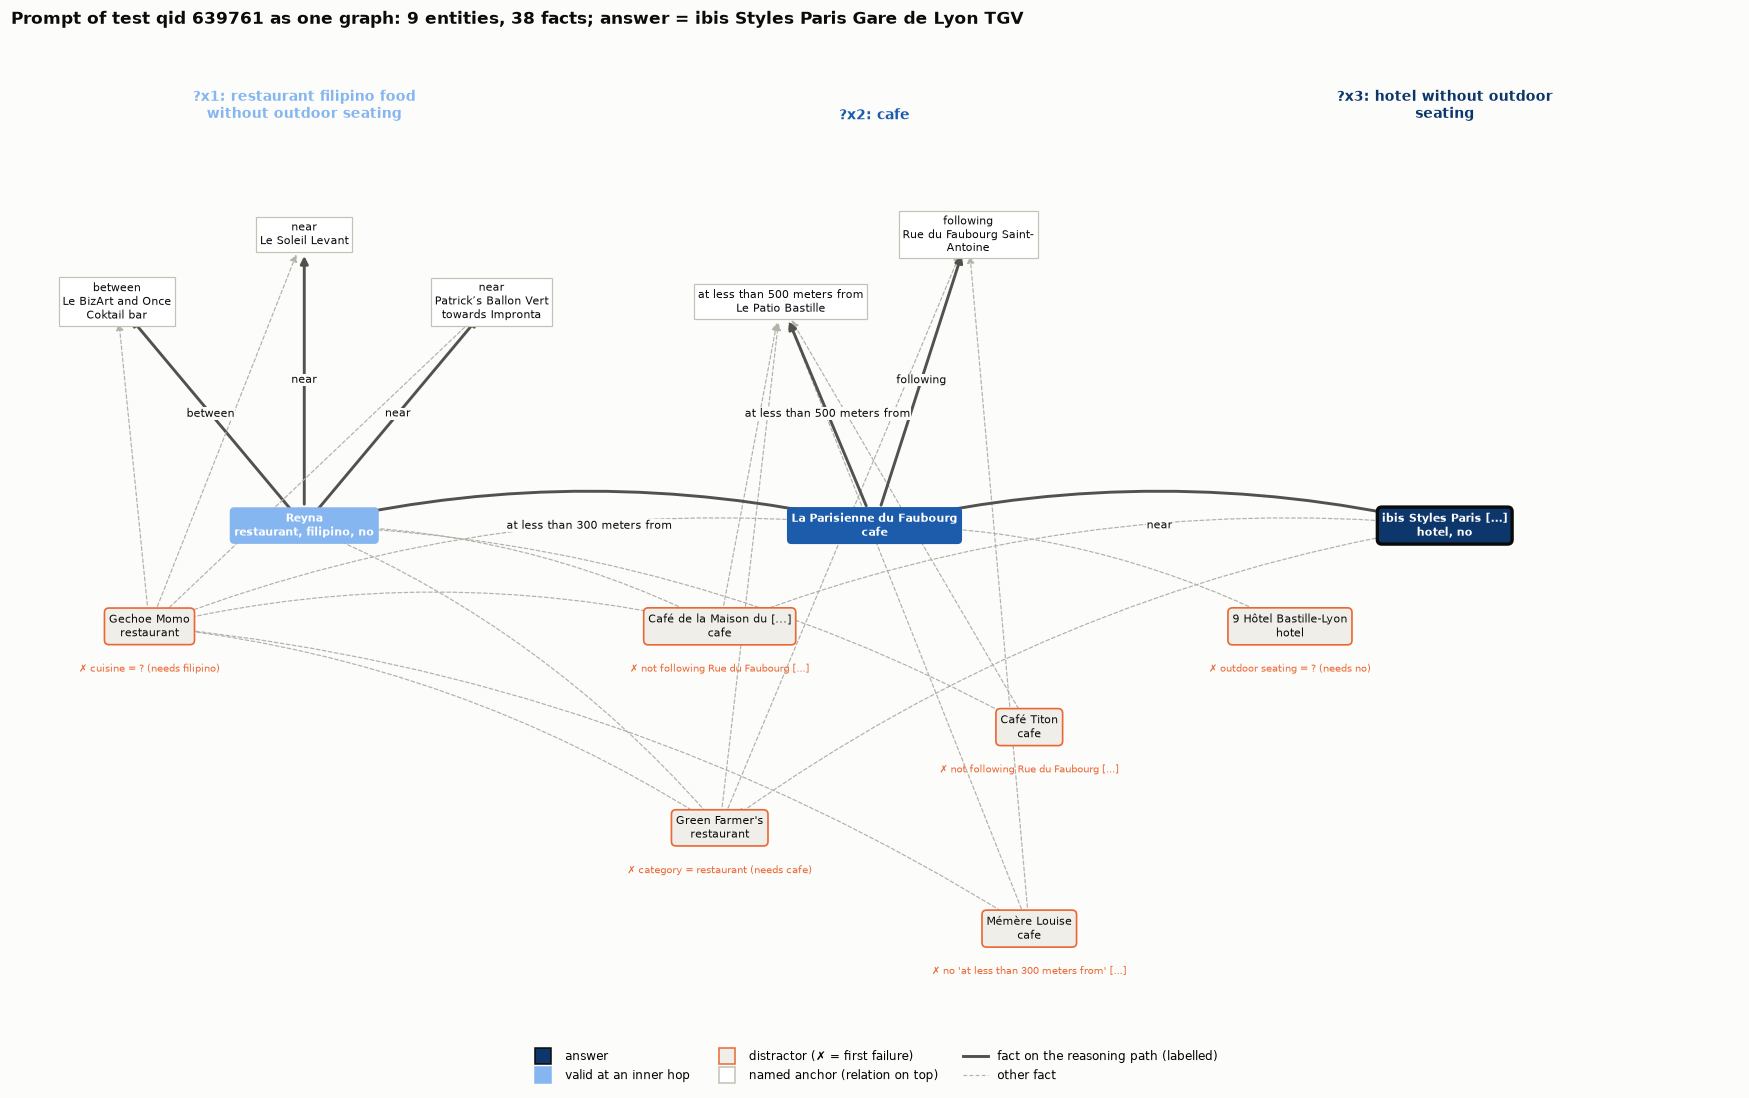

In [21]:
def single_graph(rec, ax):
    # Whole prompt as one graph: every entity and anchor once, every relation fact one labelled edge.
    # Hops are columns (?x1 left ... answer right); each hop's named anchors sit in a band above its column.
    facts, chain, hop_of, valid, why, anchors = prompt_graph(rec)
    nhop = len(chain)
    cols = [SEQ[int(i)] for i in np.linspace(0, 3, nhop).round()]
    attr_rels = set(ATTR_LABEL.values())
    X = 7.0                                             # column spacing
    pos = {}
    for i in range(nhop):                               # entities: stacked under the column
        ents = sorted([e for e, h in hop_of.items() if h == i], key=lambda e: (e not in valid[i], e.lower()))
        for k, e in enumerate(ents):
            dx = 0 if k == 0 else (-1.9 if k % 2 else 1.9)  # zig-zag so edges pass between boxes
            pos[e] = (i * X + dx, -k * 1.35)
    a_hop = {a: min(hop_of[e] for e, fs in facts.items() for p, o in fs if o == a) for a in anchors}
    a_rel = {a: next(p for fs in facts.values() for p, o in fs if o == a) for a in anchors}
    for i in range(nhop):                               # anchors: a row above the column, two staggered lines
        al = sorted([a for a in anchors if a_hop[a] == i])
        for k, a in enumerate(al):
            off = (k - (len(al) - 1) / 2) * 2.3
            pos[a] = (i * X + off, 3.0 + (0.9 if k % 2 else 0))
    # edges
    for e, fs in facts.items():
        for p, o in fs:
            if p in attr_rels or o not in pos:
                continue
            hop_edge = o in facts
            good = e in valid[hop_of[e]] and (o in valid[hop_of[o]] if hop_edge else True)
            col = C["ink2"] if good else C["other"]
            ax.add_patch(FancyArrowPatch(pos[e], pos[o], arrowstyle="-|>", mutation_scale=10, zorder=1,
                                         shrinkA=14, shrinkB=14, lw=1.9 if good else 0.8, color=col,
                                         ls="-" if good else (0, (3, 2)),
                                         connectionstyle=f"arc3,rad={0.12 if hop_edge else 0.0}"))
            if good:  # label the reasoning-path edges; other edges share the same relations (see anchor tags)
                (x0, y0), (x1, y1) = pos[e], pos[o]
                ax.text((x0 + x1) / 2, (y0 + y1) / 2, p, fontsize=7, color=C["ink"], ha="center", va="center",
                        zorder=3, bbox=dict(fc=C["surface"], ec="none", pad=0.4))
    # nodes
    for n, (x, y) in pos.items():
        if n in facts:
            i = hop_of[n]
            ok = n in valid[i]
            attrs = ", ".join(o for p, o in sorted(facts[n]) if p in attr_rels)
            ax.text(x, y, f"{textwrap.shorten(n, 26)}\n{attrs}", ha="center", va="center", fontsize=7.4, zorder=4,
                    color="white" if ok else C["ink"], fontweight="bold" if ok else "normal",
                    bbox=dict(boxstyle="round,pad=0.4", fc=cols[i] if ok else "#efeee9",
                              ec=("#0b0b0b" if i == nhop - 1 else "none") if ok else C["orange"],
                              lw=2.2 if ok and i == nhop - 1 else 1.1))
            if not ok:
                ax.text(x, y - 0.5, "✗ " + textwrap.shorten(why[n][0], 40), ha="center", va="top", fontsize=6.3,
                        color=C["orange"], zorder=4)
        else:
            ax.text(x, y, f"{a_rel[n]}\n{textwrap.fill(n, 24)}", ha="center", va="center", fontsize=7, zorder=4,
                    color=C["ink"], bbox=dict(boxstyle="square,pad=0.35", fc="white", ec=C["axis"], lw=0.8))
    for i, lvl in enumerate(chain):
        ax.text(i * X, 5.4, f"?x{i + 1}: {textwrap.fill(lvl.head, 28)}", ha="center", va="bottom", fontsize=9,
                fontweight="bold", color=cols[i])
    ys = [y for _, y in pos.values()]
    ax.set_xlim(-3.6, (nhop - 1) * X + 3.6)
    ax.set_ylim(min(ys) - 1.4, 6.6)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(16, 10))
single_graph(rec, ax)
ax.legend(handles=[
    Line2D([], [], marker="s", ls="", ms=10, color=SEQ[-1], mec="#0b0b0b", label="answer"),
    Line2D([], [], marker="s", ls="", ms=10, color=SEQ[0], label="valid at an inner hop"),
    Line2D([], [], marker="s", ls="", ms=10, color="#efeee9", mec=C["orange"], label="distractor (✗ = first failure)"),
    Line2D([], [], marker="s", ls="", ms=10, color="white", mec=C["axis"], label="named anchor (relation on top)"),
    Line2D([], [], color=C["ink2"], lw=1.9, label="fact on the reasoning path (labelled)"),
    Line2D([], [], color=C["other"], lw=0.8, ls=(0, (3, 2)), label="other fact"),
], loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=3, fontsize=8)
ax.set_title(f"Prompt of test qid {rec['qid']} as one graph: {len(prompt_graph(rec)[0])} entities, "
             f"{rec['n_facts']} facts; answer = {' | '.join(rec['answers'])}", loc="left")
plt.tight_layout()
plt.show()

## Conclusion

**Yes: OSM multi-hop can be formulated as KGQA.**
- **Linking:** all 17,443 answer ids are named POIs in `df_osm`. Question anchors link by exact name to POIs,
  streets or areas: 88.8% to a single entity, 11.2% to a name shared by several POIs, 0.04% to nothing (§5).
- **Relations:** each of the 10 relations is a deterministic geometric rule over the provided coordinates
  (§6); 99.5–100% of gold answers fall inside each fitted threshold.
- **Verification:** solving the 800 eval questions from the text and the tables alone gives 80% exact answer
  sets, recall 0.98 and Jaccard 0.92, with no drop from depth 1 to depth 4 (§8).

**To fix before turning this into a training/eval set:**
1. Deduplicate on question text.
2. Cap or filter answer-set size.
3. Resolve or drop questions whose anchor names are ambiguous.
4. Recompute the gold answers with the rules from §6, so that the context subgraph and the label agree
   exactly.
5. Choose a context policy: gold path, or retrieved neighbourhood (the `within_1000m` degree is about 870,
   so retrieval must be bounded).